# Тензори

Садржај:

1. [NumPy низови као тензори](#NumPy-низови-као-тензори)
1. [Основне операције над тензорима](#Основне-операције-над-тензорима)
1. [Специјални методи над NumPy низовима](#Специјални-методи-над-NumPy-низовима)
1. [Матризација и Расклапање (Tensor Unfolding)](#Матризација-и-Расклапање-(Tensor-Unfolding))
1. [Множење тензора](#Множење-тензора)
1. [Ајнштајнова нотација](#Ајнштајнова-нотација:-златни-стандард-AI-програмирања)

In [1]:
import numpy as np
import numpy.random as rndm
from timeit import default_timer as timer

Због природе објеката који се појављују у проблемима машинског учења уводимо још један нов математички објекат: **тензор**. Интуитивно, тензоре можемо сматрати **вишедимензионалним матрицама**. Прецизније, векторима и матрицама вишег реда.

<div>
   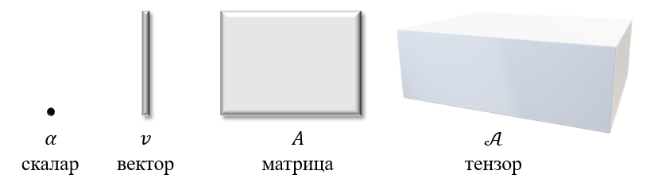  
</div>

Градација у димензионалности објеката са слике описује се кроз број индекса који су потребни да бисмо приступили њиховим елементима.

**Скалар (0-димензионални објекат)**

Скалар је у потпуности одређен једном вредношћу. Не захтева ниједан индекс.  Зато кажемо да је скалар **нула-димензионалан**.

**Вектор (тензор реда 1)**

Елементе вектора $v \in \mathbb{R}^n$ пратимо једним индексом:
- функцијски запис:  $v:\{0,1,\dots,n-1\} \to \mathbb{R}$,  $\quad v(i) = x_i$
- запис у низу:    $(x_0, x_1, \dots, x_{n-1})$
- табеларна интерпретација:

  | индекс | вредност |
  |-------|----------|
  | $0$     | $x_1$    |
  | $1$     | $x_2$    |
  | $\vdots$     | $\vdots$ |
  | $n-1$     | $x_n$    |

Пошто користи један индекс, вектор је **тензор реда 1, типа $n$**.

**Матрица (тензор реда 2)**

Матрица $A \in \mathbb{R}^{m \times n}$ захтева **два индекса**:
- функцијски запис:  $A:\{0,1,\dots,m-1\} \times \{0,1,\dots,n-1\} \to \mathbb{R}$, $\quad A(i,j) = a_{ij}$
- табеларни приказ:

  |     | $0$       | $1$       | $\dots$ | $n-1$       |
  |-----|---------|---------|---|---------|
  | $0$ | $a_{00}$ | $a_{01}$ | $\dots$ | $a_{0n-1}$ |
  | $1$ | $a_{10}$ | $a_{11}$ | $\dots$ | $a_{1n-1}$ |
  | $\vdots$ | $\vdots$  | $\vdots$|   | $\vdots$      |
  | $m-1$ | $a_{m-10}$ | $a_{m-11}$ | $\dots$ | $a_{m-1n-1}$ |

Матрица је, дакле, **тензор реда 2, типа $m \times n$**.

**Тензор вишег реда**

Тензор $\mathcal{A} \in \mathbb{R}^{m_0 \times m_1 \times \dots \times m_{n-1}}$ захтева **$n$ индекса**:
- функцијски запис:  $\mathcal{A}:\{0,\dots,m_0-1\} \times \{0,\dots,m_1-1\} \times \dots \times \{0,\dots,m_{n-1}-1\} \to \mathbb{R}$

- елемент:  $\mathcal{A}(i_0, i_1, \dots, i_{n-1}) = a_{i_0,i_1,\dots,i_{n-1}}$

Тензор $\mathcal{A}$ је **реда $n$**, типа $m_0 \times m_1 \times \dots \times m_{n-1}.$

Позиције индекса у именовању елемената тензора називамо **модови** или **осе**.  Тако, на пример, за тензор
$$
\mathcal{A} = [a_{i_0 i_1 \dots i_{n-1}}] \in \mathbb{R}^{m_0 \times m_1 \times \dots \times m_{n-1}}
$$
индекс $i_0 \in \{0,1,\dots,m_0-1\}$ припада **првом моду**, индекс $i_1 \in \{0,1,\dots,m_1-1\}$ припада **другом моду**, и тако даље.  
Позиција индекса $i_{n-1} \in \{0,1,\dots,m_{n-1}-1\}$ носи вредност **$n$-тог мода**.

Како замислити тензоре вишег реда?

Иако је тешко визуелизовати објекте са више од три димензије, у машинском учењу их посматрамо као **угњеждене (nested) структуре**:
- **Тензор 3. реда** можемо замислити као *низ матрица*.
- **Тензор 4. реда** је *низ тензора 3. реда*.
- **Тензор $n$-тог реда** је *низ тензора $(n-1)-$ог реда*.

Овај начин размишљања нам омогућава да радимо са високодимензионим подацима без потребе за геометријском визуелизацијом.

У библиотеци **NumPy**, коју ћемо користити, овај концепт се директно пресликава кроз атрибут `shape`.

***

## NumPy низови као тензори

Тензор реда $k$ је NumPy низ са $k$ оса. Као што је познато из рада са матрицама, први индекс (индекс врста) има одређену функционалну предност у NumPy низовима. Тако да би се добио објекат података који функционише као математички појам матрице њене елементе уносимо врсту по врсту. Слично је и са тензорима, требало би их уносити пресецима по индексима (slicing) по принципу угњеждених петљи пратећи распоред индекса - први индекс је у спољној петљи, последњи индекс је у најдубље постављеној петљи.

**Пример 1.** Да бисмо разумели како NumPy пакује ове податке, креираћемо тензор трећег реда. Овакав тензор можемо замислити као коцку података.

Kреираћемо тензор реда $3$ типа $2\times2\times2$ бројева од $0$ до $7$ како бисмо разумели NumPy низове у својству тензора. У те сврхе користимо комбинацију наредбе `arange` и метода `reshape`.

Позиционирање се спроводи према принципу облиаска чланова низа и угњеждених петљи индекса за позиције елемената унтар тензора, као што је приказано на слици.

<div>
   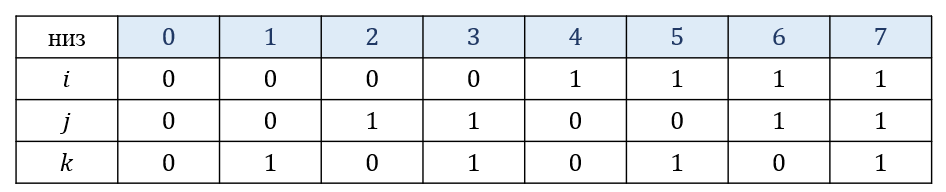  
</div>

In [2]:
T=np.arange(8).reshape(2,2,2)
T

array([[[0, 1],
        [2, 3]],

       [[4, 5],
        [6, 7]]])

In [3]:
M=np.empty((2,2,2))
elem=0
for i in range(2):
    for j in range(2):
        for k in range(2):
            M[i,j,k]=elem
            elem+=1
M            

array([[[0., 1.],
        [2., 3.]],

       [[4., 5.],
        [6., 7.]]])

Начин формирања овог тродимензионалног NumPy низа упознаћемо кроз сечења (пресеке): хоризонтална, бочна и фронтална.
- **Хоризонтална сечења:** `T[i, :, :]` Добијају се фиксирањем првог индекса. 
- **Бочна сечења:** `T[:, j, :]` Добијају се фиксирањем средњег индекса. 
- **Фронтална сечења:** `T[:, :, k]` Добијају се фиксирањем последњег индекса. 

Потражићемо хоризонталне пресеке. Примећујемо да су то управо пресеци по којима их Python приказује.

In [4]:
T[0,:,:]

array([[0, 1],
       [2, 3]])

Први индекс опет показује функционалну предност у односу на преостале индексе. За пресеке по овом индексу довољно је навођење само његове вредности.

In [5]:
T[0]

array([[0, 1],
       [2, 3]])

In [6]:
T[1]

array([[4, 5],
       [6, 7]])

Фронтална сечења:

In [7]:
T[:,:,0]

array([[0, 2],
       [4, 6]])

In [8]:
T[:,:,1]

array([[1, 3],
       [5, 7]])

Фронтални пресеци сугеришу следећи графички приказ тензора $T:$
<div>
   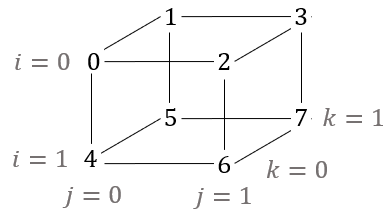  
</div>

Бочни пресеци:

In [9]:
T[:,0,:]

array([[0, 1],
       [4, 5]])

In [10]:
T[:,1,:]

array([[2, 3],
       [6, 7]])

Хоризонтално сечење у бачу слика `(batch, height, width)` издваја једну конкретну слику.  
Фронтално сечење у тензору слике `(height, width, channels)` издваја један канал боје.

Влакна су вектори који настају фиксирањем свих индекса осим једног:  
- Mode‑1 влакна (Вертикална влакна): `T[:, j, k]` (промена по првој оси).  
- Mode‑2 влакна (Хоризонтална фронтална влакна): `T[i, :, k]` (промена по другој оси).  
- Mode‑3 влакна (Хоризонтална бочна влакна): `T[i, j, :]` (промена по трећој оси). 

Нпр. све Mode‑1 векторе добијамо следећим кодом.

In [11]:
for j in range(2):
    for k in range(2):
        print(T[:,j,k],"\n")

[0 4] 

[1 5] 

[2 6] 

[3 7] 



Mode‑2 влакна:

In [12]:
for i in range(2):
    for k in range(2):
        print(T[i,:,k],"\n")

[0 2] 

[1 3] 

[4 6] 

[5 7] 



Mode‑3 влакна:

In [13]:
for i in range(2):
    for j in range(2):
        print(T[i,j,:],"\n")

[0 1] 

[2 3] 

[4 5] 

[6 7] 



***

На основу претходног примера постаје јасно како NumPy распоређује елементе у вишедимензионалном низу и како се тумаче пресеци по индексима.

У AI моделима, димензије (осе) тензора имају прецизно и недвосмислено значење. Испод су најчешћи формати по доменима.

### Табеларни подаци
**Облик:** (`batch_size`, `features`)  
**Пример:** (64, 20)  
Значење: 64 узорка, сваки са 20 карактеристика.

### Секвенце (NLP)
**Облик:** (`batch_size`, `seq_len`, `embed_dim`)  
**Пример:** (32, 512, 768)  
Значење: 32 реченице; свака има 512 токена; сваки токен је представљен вектором од 768 компоненти.

### Слике (Computer Vision)

#### TensorFlow / Keras (NHWC)
**Облик:** (`batch_size`, `height`, `width`, `channels`)  
**Пример:** (16, 224, 224, 3)  
Значење: batch од 16 RGB слика резолуције 224×224.

#### PyTorch (NCHW)
**Облик:** (`batch_size`, `channels`, `height`, `width`)  
**Пример:** (16, 3, 224, 224)  
Значење: исти подаци као горе, али са каналима на другој позицији.

### Видео (spatio-temporal data)
Видео додаје временску осу.

#### TensorFlow (NTWHC)
**Облик:** (`batch_size`, `time`, `height`, `width`, `channels`)  
**Пример:** (8, 30, 224, 224, 3)  
Значење: 8 видео-секвенци, свака са 30 фрејмова.

#### PyTorch (NCTHW)
**Облик:** (`batch_size`, `channels`, `time`, `height`, `width`)  
**Пример:** (8, 3, 30, 224, 224)

### Аудио (1D сигнали)
**Облик:** (`batch_size`, `signal_length`)  
или  
**Облик:** (`batch_size`, `channels`, `signal_length`)  

**Пример:** (32, 16000)  
Значење: 32 аудио-семпла, сваки дужине 1 секунде на 16 kHz.

### Графови (Graph Neural Networks)
Графови немају фиксне димензије као тензори, али најчешћи формати су:
- **Матрица чворова:** (`num_nodes`, `node_features`)  
- **Матрица ивица:** (`num_edges`, `edge_features`)  
- **Матрица суседства:** (`num_nodes`, `num_nodes`)  

Пример:  
- чворови: (100, 32) Значење: 100 чворова, сваки са 32 карактеристике  
- ивице: (300, 8) Значење: 300 ивица, свака са 8 карактеристика

Правилно разумевање оса је неопходно за рад са моделима, loss функцијама и batch-обрадом. Грешке у редоследу оса су један од најчешћих извора багова у ML коду. Различите библиотеке (PyTorch, TensorFlow) користе различите конвенције, што је важно при конверзији модела.

**Пример 2.**  Креираћемо тензор са следеће слике:
<div>
   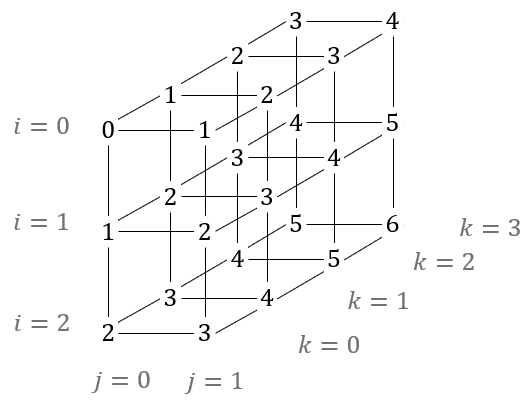  
</div>

In [14]:
lista=[[[i+j+k for k in range(4)] for j in range(2)] for i in range(3)]
A=np.array(lista)
A  #prikaz kroz horizontalne preseke

array([[[0, 1, 2, 3],
        [1, 2, 3, 4]],

       [[1, 2, 3, 4],
        [2, 3, 4, 5]],

       [[2, 3, 4, 5],
        [3, 4, 5, 6]]])

Фронтални пресеци:

In [15]:
for k in range(4):
    print(A[:,:,k],"\n")

[[0 1]
 [1 2]
 [2 3]] 

[[1 2]
 [2 3]
 [3 4]] 

[[2 3]
 [3 4]
 [4 5]] 

[[3 4]
 [4 5]
 [5 6]] 



Бочни пресеци:

In [16]:
for j in range(2):
    print(A[:,j,:],"\n")

[[0 1 2 3]
 [1 2 3 4]
 [2 3 4 5]] 

[[1 2 3 4]
 [2 3 4 5]
 [3 4 5 6]] 



Mode‑1 влакна:

In [17]:
for j in range(2):
    for k in range(4):
        print(A[:,j,k],"\n")

[0 1 2] 

[1 2 3] 

[2 3 4] 

[3 4 5] 

[1 2 3] 

[2 3 4] 

[3 4 5] 

[4 5 6] 



Mode‑2 влакна:

In [18]:
for i in range(3):
    for k in range(4):
        print(A[i,:,k],"\n")

[0 1] 

[1 2] 

[2 3] 

[3 4] 

[1 2] 

[2 3] 

[3 4] 

[4 5] 

[2 3] 

[3 4] 

[4 5] 

[5 6] 



Mode‑3 влакна:

In [19]:
for i in range(3):
    for j in range(2):
        print(A[i,j,:],"\n")

[0 1 2 3] 

[1 2 3 4] 

[1 2 3 4] 

[2 3 4 5] 

[2 3 4 5] 

[3 4 5 6] 



***

**Пример 3.** Креираћемо тензор са слике:
<div>
   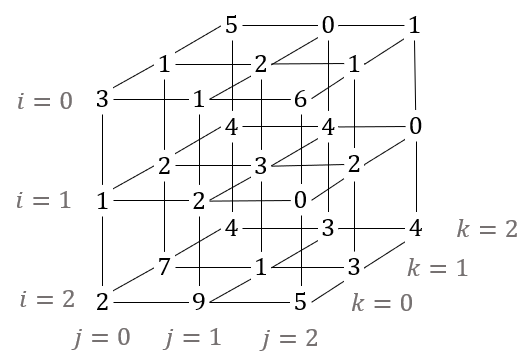  
</div>
С обзиром да елементи тензора не подлежу никаквиј правилности, уносимо их редом према хоризонталним пресецима. Проверу уноса обавићемо кроз фронталне пресеке.

In [20]:
B=np.array([[[3,1,5],[1,2,0],[6,1,1]],
            [[1,2,4],[2,3,4],[0,2,0]],
            [[2,7,4],[9,1,3],[5,3,4]]])
for k in range(3):
    print(B[:,:,k],"\n")

[[3 1 6]
 [1 2 0]
 [2 9 5]] 

[[1 2 1]
 [2 3 2]
 [7 1 3]] 

[[5 0 1]
 [4 4 0]
 [4 3 4]] 



***

**Пример 4.** Креираћемо тродимензионални нула-тензор и тензор свих јединица применом уграђених функција библиотеке NumPy.

In [21]:
O=np.zeros((2,3,2))
O

array([[[0., 0.],
        [0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.],
        [0., 0.]]])

In [22]:
E=np.ones((2,2,3))
E

array([[[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]]])

**Напомена :** Код наредби и метода где се наводи тип вишедимензионалног низа, на месту типа података `tuple`, нпр. `(2,3,2)`, могу да се користе листе, нпр. `[2,3,2]`, или низови, нпр. `np.array([2,3,2])`.

***

**Пример 5.** Помоћу функција `diag` и `eye` креираћемо тензоре посебних дијагоналних облика.
<div>
   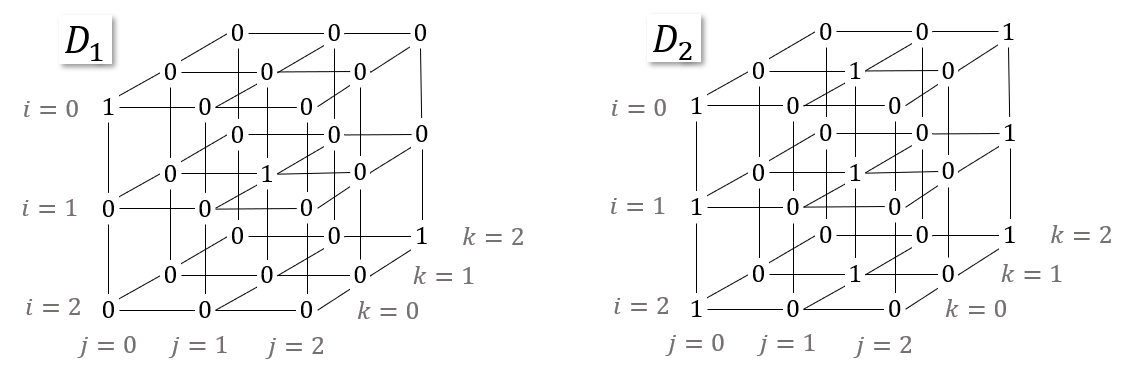  
</div>

In [23]:
D1=np.array([np.diag([1,0,0]),np.diag([0,1,0]),np.diag([0,0,1])])
for k in range(3):
    print(D1[:,:,k],"\n")   #frontalni preseci

[[1 0 0]
 [0 0 0]
 [0 0 0]] 

[[0 0 0]
 [0 1 0]
 [0 0 0]] 

[[0 0 0]
 [0 0 0]
 [0 0 1]] 



In [24]:
D2=np.array([np.eye(3),np.eye(3),np.eye(3)])
for k in range(3):
    print(D2[:,:,k],"\n")   #frontalni preseci

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]] 

[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]] 

[[0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]] 



Наредне тензоре креираћемо индексирањем.
<div>
   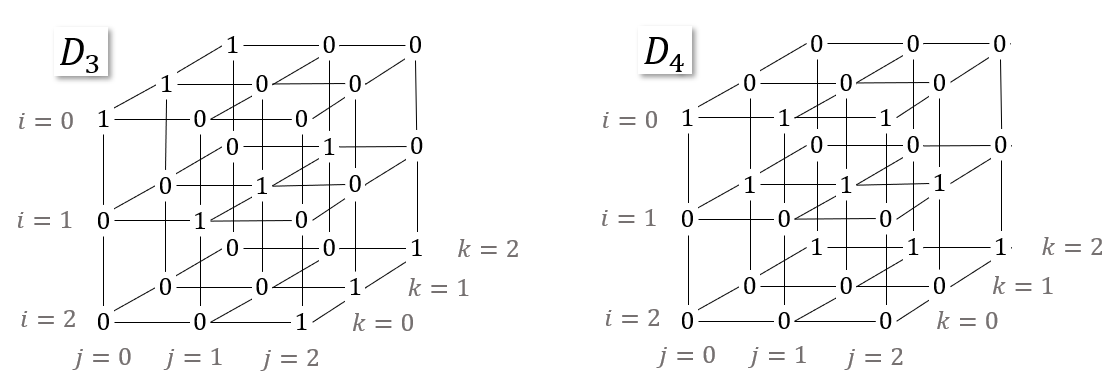  
</div>

In [25]:
D3=np.zeros((3,3,3))
for i in range(3):
    D3[i,i,:]=1
for k in range(3):
    print(D3[:,:,k],"\n")   #frontalni preseci    

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 



In [26]:
D4=np.zeros((3,3,3))
for i in range(3):
    D4[i,:,i]=1
for k in range(3):
    print(D4[:,:,k],"\n")   #frontalni preseci    

[[1. 1. 1.]
 [0. 0. 0.]
 [0. 0. 0.]] 

[[0. 0. 0.]
 [1. 1. 1.]
 [0. 0. 0.]] 

[[0. 0. 0.]
 [0. 0. 0.]
 [1. 1. 1.]] 



У свету вештачке интелигенције, избегавање `for` петљи је кључно за перформансе. Напредно индексирање у NumPy-ју омогућава да се претходни тензори креирају директно.

Тензор D3: Хоризонталне дијагонале
Желимо да поставимо вредност 1 на свим позицијама где су прва два индекса једнака ($i=j$), кроз све фронталне пресеке.

In [27]:
D3 = np.zeros((3, 3, 3))
idx = np.arange(3)
# Индексирамо прве две осе истовремено, док трећу (:) остављамо целу
D3[idx, idx, :] = 1

# Провера кроз фронталне пресеке
for k in range(3):
    print(f"Фронтални пресек k={k}:\n", D3[:, :, k], "\n")

Фронтални пресек k=0:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

Фронтални пресек k=1:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

Фронтални пресек k=2:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 



In [28]:
D4 = np.zeros((3, 3, 3))
D4[idx, :, idx] = 1

# Провера кроз фронталне пресеке
for k in range(3):
    print(f"Фронтални пресек k={k}:\n", D4[:, :, k], "\n")

Фронтални пресек k=0:
 [[1. 1. 1.]
 [0. 0. 0.]
 [0. 0. 0.]] 

Фронтални пресек k=1:
 [[0. 0. 0.]
 [1. 1. 1.]
 [0. 0. 0.]] 

Фронтални пресек k=2:
 [[0. 0. 0.]
 [0. 0. 0.]
 [1. 1. 1.]] 



Напреднији начин за креирање ових тензора је коришћење уграђених функција.

In [29]:
D3 = np.zeros((3, 3, 3))
D3[:] = np.eye(3)[:, :, None]
D3

array([[[1., 1., 1.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [1., 1., 1.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [1., 1., 1.]]])

In [30]:
D4 = np.zeros((3, 3, 3))
D4[:] = np.eye(3)[:, None, :]
D4

array([[[1., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.]],

       [[0., 1., 0.],
        [0., 1., 0.],
        [0., 1., 0.]],

       [[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.]]])

На сличан начин могу се користити и `diag` и друге уграђене функције за генерисање матрица посебне структуре.

***

## Основне операције над тензорима

Тензори, као и матрице, показују својства векторских простора. Операције сабирања и множења скаларом функционишу баш као што смо их упознали над једнодимензионалним и дводимензионалним NumPy низовима. Такође, могуће су кодне скарећинце сабирања и множења део-по-део.

**Пример 6.** На примеру тензора типа $2\times3\times4$ упознаћемо основну функционалност операција `+` и `*`.

In [31]:
A=np.arange(2*3*4).reshape(2,3,4)
B=np.array([[[(-1)**(i*(j+k)) for k in range(4)] for j in range(3)] for i in range(2)])

In [32]:
A

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

In [33]:
B

array([[[ 1,  1,  1,  1],
        [ 1,  1,  1,  1],
        [ 1,  1,  1,  1]],

       [[ 1, -1,  1, -1],
        [-1,  1, -1,  1],
        [ 1, -1,  1, -1]]])

Креирани су тензори који одговарају следећем графичком приказу:
<div>
   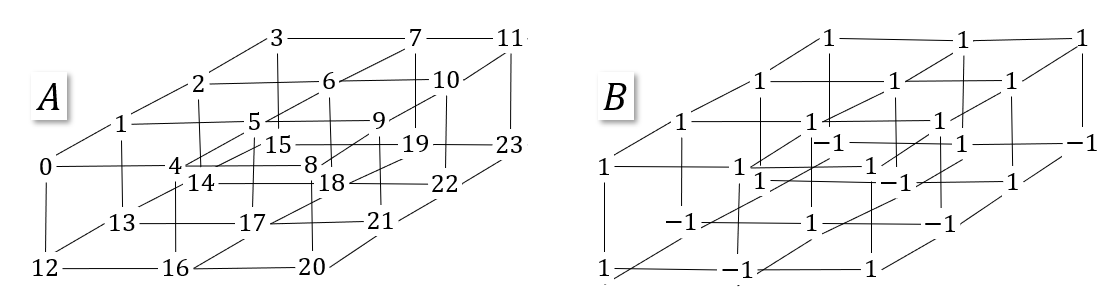  
</div>

In [34]:
A+B   #clan-po-clan sabiranje

array([[[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]],

       [[13, 12, 15, 14],
        [15, 18, 17, 20],
        [21, 20, 23, 22]]])

In [35]:
A-B

array([[[-1,  0,  1,  2],
        [ 3,  4,  5,  6],
        [ 7,  8,  9, 10]],

       [[11, 14, 13, 16],
        [17, 16, 19, 18],
        [19, 22, 21, 24]]])

Нумеричка снага NumPy-ја лежи у бродкастингу. При бродкастингу, NumPy упоређује димензије тензора с десна на лево. Димензије су компатибилне ако су једнаке или је једна од њих једнака 1. Ако су димензије тензора  
$$A \in \mathbb{R}^{d_1 \times \cdots \times d_k},\qquad B \in \mathbb{R}^{e_1 \times \cdots \times e_k},$$  
онда је операција члан‑по‑члан дефинисана ако за свако $i$ важи:  
$$d_i = e_i\quad \text{ или}\quad d_i = 1\quad \text{ или}\quad e_i = 1.$$
Овај механизам омогућава операције над тензорима који немају исте редове, тако што се мањи тензор развлачи преко већег. У AI архитектурама, ово је кључно за додавање вектора пристрасности (bias) излазу неуронског слоја. 

Кодним скраћеницама можемо свим елементима тензора да додамо исту вредност (скалар) или делове другог тензора.

In [36]:
A-5   #clan-po-clan oduzimanje

array([[[-5, -4, -3, -2],
        [-1,  0,  1,  2],
        [ 3,  4,  5,  6]],

       [[ 7,  8,  9, 10],
        [11, 12, 13, 14],
        [15, 16, 17, 18]]])

In [37]:
print(A)
print(B[1])
A+B[1]  #matrica-po-matrica sabiranje, razvlacenje matrice preko prve ose

[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]
[[ 1 -1  1 -1]
 [-1  1 -1  1]
 [ 1 -1  1 -1]]


array([[[ 1,  0,  3,  2],
        [ 3,  6,  5,  8],
        [ 9,  8, 11, 10]],

       [[13, 12, 15, 14],
        [15, 18, 17, 20],
        [21, 20, 23, 22]]])

Шематски приказ ове кодне скраћенице дат је наредном сликом.
<div>
   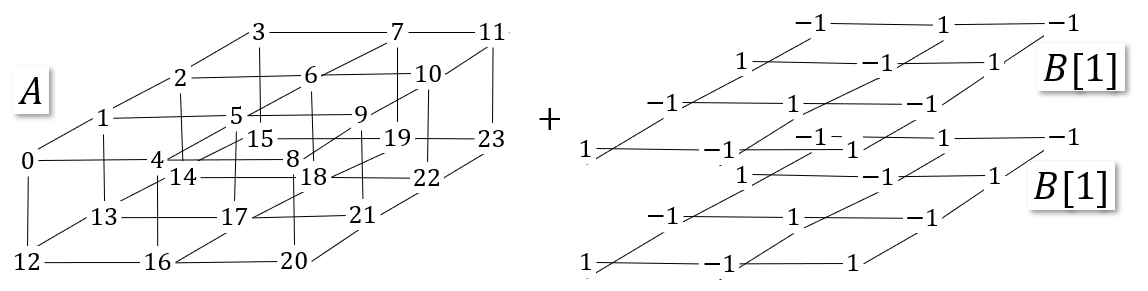  
</div>

Слично можемо вршити сабирање по осталим осама, користећи reshape како бисмо омогућили бродкастингу да препозна које осе треба развући.

In [38]:
A+B[:,1,:].reshape(2,1,4)  #matrica-po-matrica sabiranje po bocnim presecima

array([[[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]],

       [[11, 14, 13, 16],
        [15, 18, 17, 20],
        [19, 22, 21, 24]]])

`reshape` се овде користи искључиво да би се појавила димензија 1 која омогућава бродкастинг. Уметање димензије 1 помоћу `reshape` или `np.newaxis` не мења податке у меморији, већ само начин на који NumPy тумачи осе тензора. Шематски приказ претходне кодне скраћенице дат је наредном сликом.
<div>
   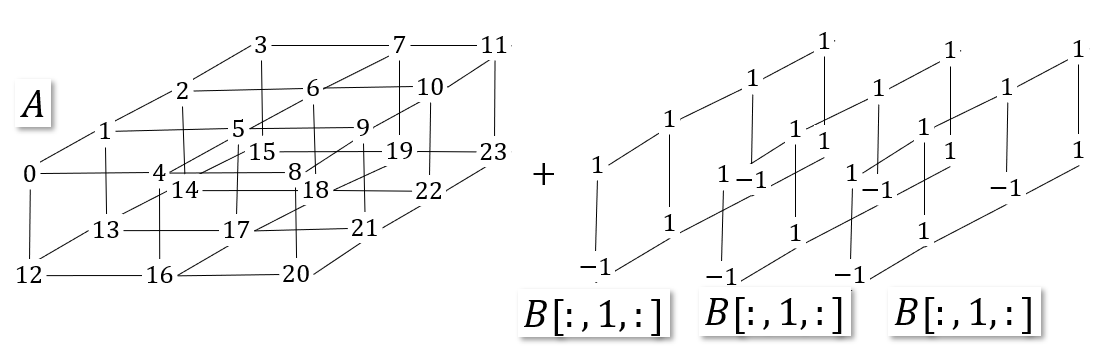  
</div>

In [39]:
A+B[:,:,2].reshape(2,3,1)  #matrica-po-matrica sabiranje po frontalnim presecima

array([[[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]],

       [[13, 14, 15, 16],
        [15, 16, 17, 18],
        [21, 22, 23, 24]]])

Шематски приказ претходне кодне скраћенице дат је наредном сликом.
<div>
   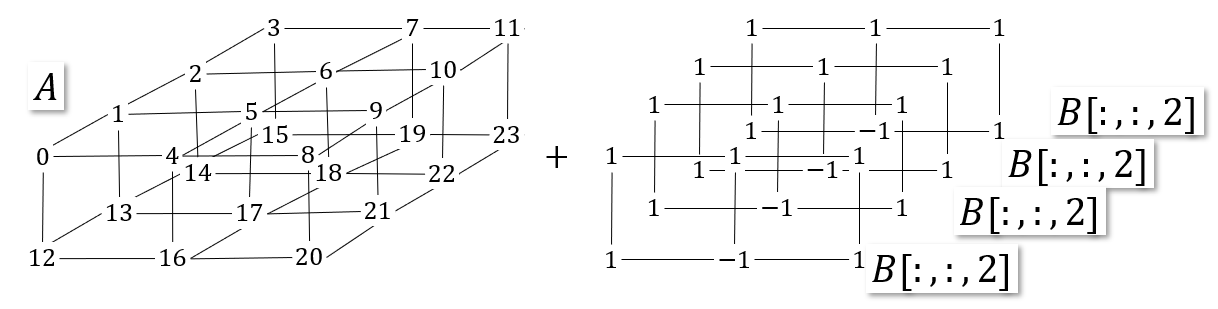  
</div>

Слично функционише вектор-по-вектор сабирање. Наредна програмска скраћеница обавља операцију која је шематски приказана сликом.

<div>
   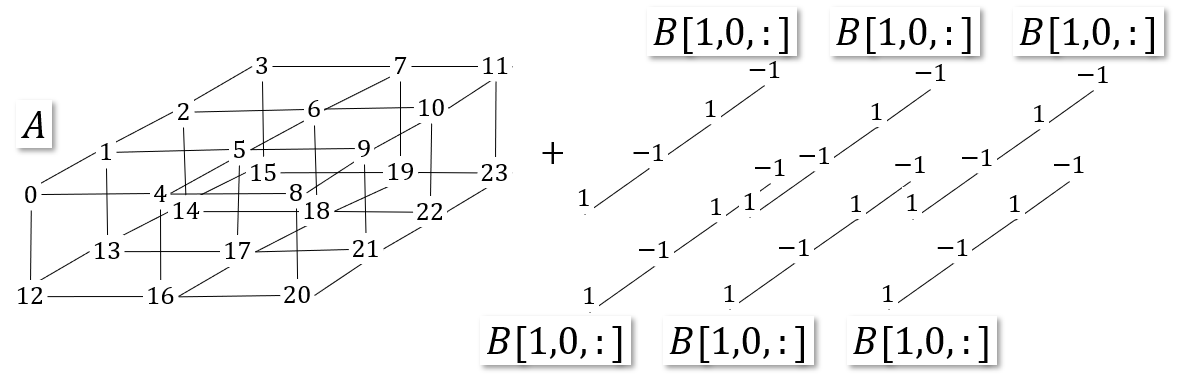  
</div>

In [40]:
A+B[1,0,:]  #vektor-po-vektor sabiranje mod-3 vektora

array([[[ 1,  0,  3,  2],
        [ 5,  4,  7,  6],
        [ 9,  8, 11, 10]],

       [[13, 12, 15, 14],
        [17, 16, 19, 18],
        [21, 20, 23, 22]]])

<div>
   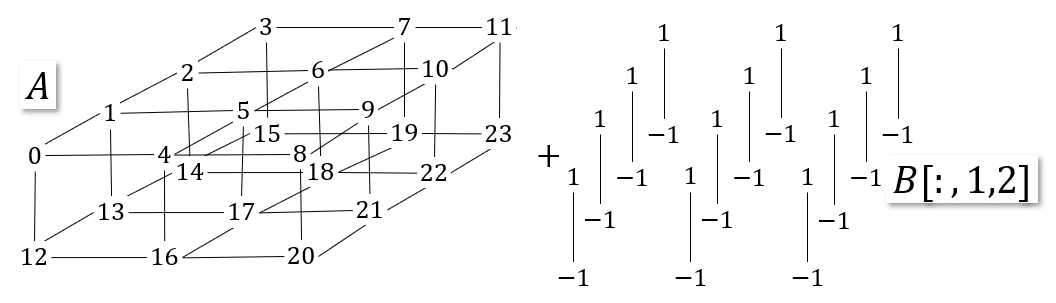  
</div>

In [41]:
A+B[:,1,2].reshape(2,1,1)  #vektor-po-vektor sabiranje mod-1 vektora

array([[[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]],

       [[11, 12, 13, 14],
        [15, 16, 17, 18],
        [19, 20, 21, 22]]])

На исти начин функционишу операција `*` и програмске скраћенице са њом. Приликом степеновања или дељења у ML моделима, важно је водити рачуна о нумеричкој стабилности (нпр. избегавање дељења нулом).

In [42]:
A*B   #clan-po-clan mnozenje = Adamarov proivod

array([[[  0,   1,   2,   3],
        [  4,   5,   6,   7],
        [  8,   9,  10,  11]],

       [[ 12, -13,  14, -15],
        [-16,  17, -18,  19],
        [ 20, -21,  22, -23]]])

In [43]:
A*3   #clan-po-clan mnozenje jednim brojem = skaliranje

array([[[ 0,  3,  6,  9],
        [12, 15, 18, 21],
        [24, 27, 30, 33]],

       [[36, 39, 42, 45],
        [48, 51, 54, 57],
        [60, 63, 66, 69]]])

In [44]:
A*B[1]  #matrica-po-matrica množenje po horizontalnim presecima

array([[[  0,  -1,   2,  -3],
        [ -4,   5,  -6,   7],
        [  8,  -9,  10, -11]],

       [[ 12, -13,  14, -15],
        [-16,  17, -18,  19],
        [ 20, -21,  22, -23]]])

In [45]:
A*B[:,1,:].reshape(2,1,4)  #matrica-po-matrica množenje po bocnim presecima

array([[[  0,   1,   2,   3],
        [  4,   5,   6,   7],
        [  8,   9,  10,  11]],

       [[-12,  13, -14,  15],
        [-16,  17, -18,  19],
        [-20,  21, -22,  23]]])

In [46]:
A*B[1,0,:]  #vektor-po-vektor množenje horizontalnih bočnih vektora

array([[[  0,  -1,   2,  -3],
        [  4,  -5,   6,  -7],
        [  8,  -9,  10, -11]],

       [[ 12, -13,  14, -15],
        [ 16, -17,  18, -19],
        [ 20, -21,  22, -23]]])

In [47]:
A*B[:,1,2].reshape(2,1,1)  #vektor-po-vektor množenje vertikalnih vektora

array([[[  0,   1,   2,   3],
        [  4,   5,   6,   7],
        [  8,   9,  10,  11]],

       [[-12, -13, -14, -15],
        [-16, -17, -18, -19],
        [-20, -21, -22, -23]]])

Исто се понашају и остале основне аритметичке операције као што су дељење `/`, целобројно дељење `//` или остатак при целобројном дељењу `%`, степеновање `**`... Такође, основне математичке функције се примењују члан по члан. Остаје, јасно питање области дефинисаности примењених функција. На пример, дељење нулом ће произвести NaN вредност. Код степеновања потребно је водити рачуна о знаку степена уколико се ради о низу целобројних вредности или низу природних бројева. 

In [48]:
A/(2*B)

array([[[  0. ,   0.5,   1. ,   1.5],
        [  2. ,   2.5,   3. ,   3.5],
        [  4. ,   4.5,   5. ,   5.5]],

       [[  6. ,  -6.5,   7. ,  -7.5],
        [ -8. ,   8.5,  -9. ,   9.5],
        [ 10. , -10.5,  11. , -11.5]]])

In [49]:
B/A

C:\Users\jovan\AppData\Local\Temp\ipykernel_12456\2512182345.py:1: RuntimeWarning: divide by zero encountered in divide
  B/A


array([[[        inf,  1.        ,  0.5       ,  0.33333333],
        [ 0.25      ,  0.2       ,  0.16666667,  0.14285714],
        [ 0.125     ,  0.11111111,  0.1       ,  0.09090909]],

       [[ 0.08333333, -0.07692308,  0.07142857, -0.06666667],
        [-0.0625    ,  0.05882353, -0.05555556,  0.05263158],
        [ 0.05      , -0.04761905,  0.04545455, -0.04347826]]])

In [50]:
A**2

array([[[  0,   1,   4,   9],
        [ 16,  25,  36,  49],
        [ 64,  81, 100, 121]],

       [[144, 169, 196, 225],
        [256, 289, 324, 361],
        [400, 441, 484, 529]]])

In [51]:
A**(-1)

ValueError: Integers to negative integer powers are not allowed.

In [52]:
A**(B+1)

array([[[  0,   1,   4,   9],
        [ 16,  25,  36,  49],
        [ 64,  81, 100, 121]],

       [[144,   1, 196,   1],
        [  1, 289,   1, 361],
        [400,   1, 484,   1]]])

In [53]:
(A.astype(np.float64))**B

array([[[ 0.        ,  1.        ,  2.        ,  3.        ],
        [ 4.        ,  5.        ,  6.        ,  7.        ],
        [ 8.        ,  9.        , 10.        , 11.        ]],

       [[12.        ,  0.07692308, 14.        ,  0.06666667],
        [ 0.0625    , 17.        ,  0.05555556, 19.        ],
        [20.        ,  0.04761905, 22.        ,  0.04347826]]])

Многе активационе функције у неуронским мрежама примењују се члан-по-члан над тензором, нпр. ReLU (Rectified Linear Unit). Активација је заправо операција `max(0,x)` примењена члан-по-члан на цео тензор.

In [54]:
relu_out = np.maximum(0, B)
relu_out

array([[[1, 1, 1, 1],
        [1, 1, 1, 1],
        [1, 1, 1, 1]],

       [[1, 0, 1, 0],
        [0, 1, 0, 1],
        [1, 0, 1, 0]]])

Вишедимензионални низови истог типа могу да се користе и као границе за генерисање прелаза између стања (нпр. за морфинг или интерполацију тежина) користећи функцију `linspace()`.

In [55]:
# Generisanje 5 tenzora koji linearno prelaze iz A u 2*A
C=np.linspace(A,2*A,5)
C.shape

(5, 2, 3, 4)

In [56]:
C

array([[[[ 0.  ,  1.  ,  2.  ,  3.  ],
         [ 4.  ,  5.  ,  6.  ,  7.  ],
         [ 8.  ,  9.  , 10.  , 11.  ]],

        [[12.  , 13.  , 14.  , 15.  ],
         [16.  , 17.  , 18.  , 19.  ],
         [20.  , 21.  , 22.  , 23.  ]]],


       [[[ 0.  ,  1.25,  2.5 ,  3.75],
         [ 5.  ,  6.25,  7.5 ,  8.75],
         [10.  , 11.25, 12.5 , 13.75]],

        [[15.  , 16.25, 17.5 , 18.75],
         [20.  , 21.25, 22.5 , 23.75],
         [25.  , 26.25, 27.5 , 28.75]]],


       [[[ 0.  ,  1.5 ,  3.  ,  4.5 ],
         [ 6.  ,  7.5 ,  9.  , 10.5 ],
         [12.  , 13.5 , 15.  , 16.5 ]],

        [[18.  , 19.5 , 21.  , 22.5 ],
         [24.  , 25.5 , 27.  , 28.5 ],
         [30.  , 31.5 , 33.  , 34.5 ]]],


       [[[ 0.  ,  1.75,  3.5 ,  5.25],
         [ 7.  ,  8.75, 10.5 , 12.25],
         [14.  , 15.75, 17.5 , 19.25]],

        [[21.  , 22.75, 24.5 , 26.25],
         [28.  , 29.75, 31.5 , 33.25],
         [35.  , 36.75, 38.5 , 40.25]]],


       [[[ 0.  ,  2.  ,  4.  ,  6.  ],
 

Један од најважнијих аспеката операција над тензорима су редукције – операције које смањују ред тензора (сума, просек, максимум). Оне се користе за израчунавање Loss функције или у Pooling слојевима.

In [57]:
# Ukupna suma svih elemenata (npr. za regularizaciju)
total_sum = np.sum(A)
print(total_sum)

# Prosečna vrednost po batch-u (npr. prosek intenziteta piksela po slikama)
# axis=0 znači da vršimo redukciju po prvoj osi
batch_mean = np.mean(A, axis=(1, 2))
print(batch_mean)

# Maksimum po osi (Osnova za Max-Pooling u konvolucionim mrežama)
pooling_sim = np.max(A, axis=2)
print(pooling_sim)
print(A)

276
[ 5.5 17.5]
[[ 3  7 11]
 [15 19 23]]
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]


**Напомена:** Редукција по одређеној оси значи да се та оса „укида“ (агрегира) применом операције, а резултат задржава све преостале осе. Ако је тензор био реда 3, након редукције по једној оси, он постаје тензор реда 2 (матрица).

***

## Специјални методи над NumPy низовима 

Операције из овог одељка не мењају распоред података у меморији, већ само мењају начин на који NumPy интерпретира индексе (тзв. view над истим подацима). Разлог зашто су ове операције веома брзе је што се не мењају подаци, већ само кораци (stride) којима NumPy прелази кроз меморију. NumPy по дифолту чува елементе у меморији у C-order поретку, што значи да се последња оса најбрже мења при обиласку елемената.

Атрибут транспоновања `.T` врши замену редоследа индекса у вишедимезионалном низу тако што редослед индекса преокрене наопачке.
$$A(i_1,i_2,\dots,i_n)\quad\stackrel{T}{\mapsto}\quad A(i_n,\dots,i_2,i_1).$$
За тензоре реда већег од 2, операција `.T` не представља транспоновање у класичном смислу (као код матрица), већ специфичну пермутацију свих оса у обрнутом редоследу.

In [58]:
A

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

In [59]:
A.shape, A.T.shape

((2, 3, 4), (4, 3, 2))

In [60]:
A.T

array([[[ 0, 12],
        [ 4, 16],
        [ 8, 20]],

       [[ 1, 13],
        [ 5, 17],
        [ 9, 21]],

       [[ 2, 14],
        [ 6, 18],
        [10, 22]],

       [[ 3, 15],
        [ 7, 19],
        [11, 23]]])

In [61]:
for k in range(4):
    print(A[:,:,k].T,"\n")

[[ 0 12]
 [ 4 16]
 [ 8 20]] 

[[ 1 13]
 [ 5 17]
 [ 9 21]] 

[[ 2 14]
 [ 6 18]
 [10 22]] 

[[ 3 15]
 [ 7 19]
 [11 23]] 



За прецизнију контролу користимо метод `transpose([permutacija])`.  Без навођења опционог аргумента `permutacija` овај метод даје исти излаз као и атрибут `.T` Општа пермутација оса тензора представља композицију индекса:
$$
B(i_1, \ldots, i_n) = A\bigl(i_{\pi(1)}, \ldots, i_{\pi(n)}\bigr),
$$
где је $\pi$ пермутација скупа $\{1, \ldots, n\}$.

In [62]:
A.transpose((0,2,1))

array([[[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]],

       [[12, 16, 20],
        [13, 17, 21],
        [14, 18, 22],
        [15, 19, 23]]])

In [63]:
A.transpose((0,2,1)).shape

(2, 4, 3)

У дубоком учењу, различите библиотеке користе различите распореде канала за слике.  
Метод `transpose` је неопходан за конверзију између ових формата:

**NCHW** (нпр. PyTorch): `(batch, channels, height, width)`  
**NHWC** (нпр. TensorFlow): `(batch, height, width, channels)`

Уколико бисмо желели испис низа A кроз фронтална сечења, то можемо да постигнемо следећим кодом.

In [64]:
A.transpose((2,0,1))

array([[[ 0,  4,  8],
        [12, 16, 20]],

       [[ 1,  5,  9],
        [13, 17, 21]],

       [[ 2,  6, 10],
        [14, 18, 22]],

       [[ 3,  7, 11],
        [15, 19, 23]]])

In [65]:
A.transpose((2,0,1)).shape

(4, 2, 3)

Додатну флексибилност пружају рутине [rollaxis()](https://numpy.org/doc/stable/reference/generated/numpy.rollaxis.html), [moveaxis()](https://numpy.org/doc/stable/reference/generated/numpy.moveaxis.html) и [swapaxes()](https://numpy.org/doc/stable/reference/generated/numpy.swapaxes.html)  које омогућавају померање конкретне осе на нову позицију без навођења целе пермутације.

In [66]:
np.moveaxis(A,-1,0).shape

(4, 2, 3)

In [67]:
np.moveaxis(A,1,-1).shape

(2, 4, 3)

In [68]:
np.swapaxes(A,1,-1).shape

(2, 4, 3)

In [69]:
np.swapaxes(A,0,1).shape

(3, 2, 4)

***

## Матризација и Расклапање (Tensor Unfolding)

У литератури која се бави тензорским декомпозицијама (нпр. CP или Tucker), операције над тензорима се често изводе тако што се тензор расклопи у матрицу. Ово нам омогућава да користимо моћне алате стандардне линеарне алгебре (као што су SVD или QR декомпозиција) над вишедимензионалним подацима. Када тензор расклопимо у матрицу и над њом извршимо SVD, ми заправо проналазимо главне компоненте варијације дуж тог конкретног мода. Ова процедура (примењена на све модове) чини [HOSVD декомпозицију](https://en.wikipedia.org/wiki/Higher-order_singular_value_decomposition), која се користи за компресију видео снимака и анализу мултимодалних података (нпр. препознавање лица под различитим угловима и осветљењем).

Кључни термини:
- **Влакна (Fibers):** Вектори добијени фиксирањем свих индекса осим једног (нпр. вертикална влакна).
- **Сечења (Slices):** Матрице добијене фиксирањем свих индекса осим два (нпр. фронтални пресеци).
- **Расклапање (Unfolding/Flattening):** Процес претварања тензора у матрицу дуж одређеног мода (димензије).

Методом `reshape()` можемо да извршимо матризацију или линеаризацију тензора. Овом наредбом се по принципу угњеждених петљи обилазе елементи вишедимезионалног низа и уписују у матрице или друге вишедимензионалне низове. 

**Дефиниција 1.** Расклапање тензора $\mathcal{A}\in \mathcal{M}_{m_0\times m_1\times \dots \times m_{n-1}}$ по $k$‑том модy означавамо са $\mathcal{A}_{[k]}$, а оно представља пресликавање
$$
\mathcal{M}_{m_0\times m_1\times \dots \times m_{n-1}}
\;\mapsto\;
\mathcal{M}_{\,m_k \times (m_0\cdots m_{k-1}m_{k+1}\cdots m_{n-1})}
$$
$$
\mathcal{A} \;\mapsto\; \mathcal{A}_{[k]}.
$$

Расклапање тензора по моду $k$ је матрица чије су врсте управо влакна тензора дуж тог мода. Свако расклапање тензора по моду може се добити комбинацијом пермутације оса (`transpose`) и матризацијом или линеаризације (`reshape`).

**Пример 7.** Расклапање тензора са слике по свим модовима гласе: 
<div>
   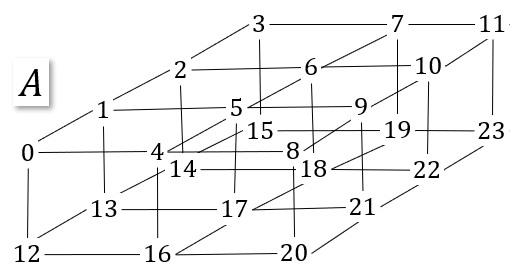  
</div>
\begin{align}
&\mathcal{A}_{[0]}=\left[\begin{array}
{cccc|cccc|cccc}
0&1&2&3&4&5&6&7&8&9&10&11\\
12&13&14&15&16&17&18&19&20&21&22&23
\end{array}\right],\\
&\mathcal{A}_{[1]}=\left[\begin{array}
{cccc|cccc}
0&1&2&3&12&13&14&15\\
4&5&6&7&16&17&18&19\\
8&9&10&11&20&21&22&23
\end{array}\right],\\
&\mathcal{A}_{[2]}=\left[\begin{array}
{ccc|ccc}
0&4&8&12&16&20\\
1&5&9&13&17&21\\
2&6&10&14&18&22\\
3&7&11&15&19&23
\end{array}\right].
\end{align}

Разлагање по првом моду добијамо наредним кодом. Приметимо да овде није потребан `transpose`, јер је мод 1 већ прва оса у C-order обиласку.

In [70]:
# Razlaganje po prvom modu (Mode-1 unfolding)
A0=A.reshape(2,3*4)
A0

array([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11],
       [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]])

Како би лакше разумели формирање матрице, искористићемо обилазак елемената секвенцијално.

In [71]:
M=np.empty((2,3*4))
for i in range(2):
    for j in range(3):
        for k in range(4):
            ivrsta=(k+4*j+3*4*i)//12
            ikolona=(k+4*j+3*4*i)%12
            M[ivrsta,ikolona]=A[i,j,k]
M            

array([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.],
       [12., 13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23.]])

Истим методом вршимо склапање натраг тензора по првом моду, тј. моду $0$ у Python начину индексирања. Упоредићемо ефекат метода `reshape` са полазним тензором $A.$

In [72]:
A0.reshape(2,3,4)

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

In [73]:
A

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

Расклапање по другом и трећем моду добија се слично. Потребно је претходно извршити одговарајућу пермутацију модова како би се обезбедио одговарајући редослед "угњеждених петљи" обиласка елемената.

In [74]:
A1=np.transpose(A,(1,0,2)).reshape(3,2*4)
A1

array([[ 0,  1,  2,  3, 12, 13, 14, 15],
       [ 4,  5,  6,  7, 16, 17, 18, 19],
       [ 8,  9, 10, 11, 20, 21, 22, 23]])

Истим методом `reshape` вршимо и обрнуту операцију – враћање података у тензорски облик. 

**Напомена:** Приликом склапања, неопходно је користити инверзну пермутацију индекса ако је претходно вршено транспоновање за потребе расклапања. 

In [75]:
np.transpose(A1.reshape(3,2,4),(1,0,2))

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

In [76]:
A2=np.transpose(A,(2,0,1)).reshape(4,2*3)
A2

array([[ 0,  4,  8, 12, 16, 20],
       [ 1,  5,  9, 13, 17, 21],
       [ 2,  6, 10, 14, 18, 22],
       [ 3,  7, 11, 15, 19, 23]])

In [77]:
np.transpose(A2.reshape(4,2,3),(1,2,0))

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

И векторизација тензора је директна методом `reshape()`. Операција $vec(A)$ или потпуна линеаризација тензора користи се у Flatten слојевима конволуционих мрежа. Она претвара 3D мапу карактеристика у 1D вектор како би се подаци могли проследити потпуно повезаном (Dense) слоју. Векторизација тензора је посебан случај расклапања по свим модовима и представља основни корак у формулацији тензорских операција помоћу Кронекеровог производа.

In [78]:
vecA=A.reshape(2*3*4,)
vecA

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23])

In [79]:
vecA.reshape(2,3,4)

array([[[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]],

       [[12, 13, 14, 15],
        [16, 17, 18, 19],
        [20, 21, 22, 23]]])

In [80]:
vecA = A.reshape(-1) # Automatski izračunava ukupnu dužinu
print("Oblik vektorizovanog tenzora:", vecA.shape)

Oblik vektorizovanog tenzora: (24,)


In [ ]:
vecA

Важно је разумети да операције `reshape` и `transpose` у NumPy-ју углавном не копирају податке у меморији. Оне креирају нови 'view' мењајући само 'strides' (кораке кроз меморију). Зато је расклапање тензора од неколико гигабајта у матрицу тренутна операција која не заузима додатни RAM, што је кључно за обраду великих бачева података.

**Напомена:** Док смо код Кронекеровог производа користили order='F' ради усклађивања са класичном матричном теоријом, у тензорским библиотекама се чешће користи подразумевани order='C'. Важно је само бити конзистентан: ако се тензор расклопи по једном поретку, мора се истим поретком и склопити натраг.

***

## Множење тензора

У тензорској алгебри постоји неколико врста множења, зависно од тога да ли желимо да повећамо ред тензора (спољашњи производи) или да га смањимо (контракције).

**Дефиниција 2.**  (Тензорски/спољашњи производ) Нека су $A$ и $B$ тензори редова $n$ и $r$.  
Њихов тензорски производ $C = A \otimes B$ је тензор реда $(n+r)$  
чији су елементи сви могући производи елемената фактора:
$$
C_{i_1 \dots i_n\, j_1 \dots j_r}
=
A_{i_1 \dots i_n}\,\cdot\, B_{j_1 \dots j_r}.
$$

Тензорски производ из ове дефиниције у NumPy-ју  добија се наредбом `tensordot` навођењем опције `axes=0`.

In [82]:
print(A.shape)
print(B.shape)

(2, 3, 4)
(2, 3, 4)


In [83]:
np.tensordot(A,B,axes=0).shape

(2, 3, 4, 2, 3, 4)

**Веза са Кронекеровим производом:**
Кронекеров производ матрица $A \otimes B$ је заправо матрична верзија њиховог тензорског спољашњег производа.  
Док тензорски производ чува димензије фактора у одвојеним осама (нпр. из две матрице добија се тензор 4. реда),  
Кронекеров производ их „пакује” у једну велику матрицу (тензор 2. реда).

**Пример 8.** Нека су матрице $M_1 \in \mathcal{M}_{2\times 2}$ и  $M_2 \in \mathcal{M}_{3\times 3}.$ Тензорски (спољашњи) производ је
$$
T_{i_1 i_2 j_1 j_2} = (M_1)_{i_1 i_2}\,(M_2)_{j_1 j_2},
\qquad
T \in \mathcal{M}_{2\times 2\times 3\times 3}.$$

In [84]:
M1=rndm.rand(2,2)
M2=rndm.rand(3,3)
T=np.tensordot(M1,M2,axes=0)
T.shape

(2, 2, 3, 3)

Расклапање тензора које групише индексе као $(i_1,j_1)$ за редове и $(i_2,j_2)$ за колоне даје матрицу:
$$
T_{[(0,2),(1,3)]} \in \mathcal{M}_{(2\cdot 3)\times(2\cdot 3)} = \mathcal{M}_{6\times 6}.
$$
Тада важи:
$$
T_{[(0,2),(1,3)]} = M_1 \otimes M_2,
$$
односно Кронекеров производ је расклапање тензорског производа уз другачије груписање оса.

In [85]:
T_unfold = T.transpose(0,2,1,3).reshape(6,6)
K = np.kron(M1, M2)
print("Да ли се поклапају:", np.allclose(T_unfold, K))

Да ли се поклапају: True


Дакле, Кронекеров производ није нова алгебарска операција, већ последица другачије организације индекса тензорског производа.

***

**Пример 9. Веза са Катри‑Рао производом:**  

Док је Кронекеров производ везан за „паковање” комплетних простора, **Катри–Рао производ ($\odot$)** је кључан за рад са тензорским компонентама. У вештачкој интелигенцији, он је „мотор” за **CP декомпозицију** (*Canonical Polyadic Decomposition*), која омогућава екстремну компресију великих вишедимензионалних података.
Ако уведемо ознаке колона
$$A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}\\
A_0&A_1&\dots&A_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right],\qquad 
B=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}\\
B_0&B_1&\dots&B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}
\end{array}\right],
$$
тада су колоне матрице $C=A\odot B$ дате са:
$$C=A\odot B=A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WWW}&\phantom{W}\\
A_0\otimes B_0&A_1\otimes B_1&\dots&A_{n-1}\otimes B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right].$$

Ако је тензор $X$ добијен из три матрице фактора $A, B, C$, његово расклапање по првом моду се изражава као:
$$
X_{[0]} = A \,(C \odot B)^{T}.
$$
Ово омогућава да се операције над огромним тензорима изводе ефикасно коришћењем само малих матрица фактора.

In [86]:
def khatri_rao(M1, M2):
    """Pomoćna funkcija za Khatri-Rao proizvod (Kronecker po kolonama)"""
    # Provera: matrice moraju imati isti broj kolona (zajednički rang R)
    assert M1.shape[1] == M2.shape[1]
    R = M1.shape[1]
    # np.kron primenjen kolonu-po-kolonu
    return np.column_stack([np.kron(M1[:, r], M2[:, r]) for r in range(R)])

In [87]:
# Definisanje dimenzija i faktora sa zajedničkim rangom R=2
I, J, K, R = 2, 3, 4, 2
A = np.random.rand(I, R)
B = np.random.rand(J, R)
C = np.random.rand(K, R)

# 1. Konstrukcija originalnog tenzora X iz CP komponenti
# X_ijk = sum_r (A_ir * B_jr * C_kr)
X = np.zeros((I, J, K))
for r in range(R):
    # Spoljašnji proizvod a_r, b_r i c_r daje tenzor (I x J x K)
    # np.multiply.outer je najčistiji način za spoljašnji proizvod vektora
    outer_bc = np.multiply.outer(B[:, r], C[:, r])
    X += np.multiply.outer(A[:, r], outer_bc)

# 2. Rekonstrukcija unfoldinga X[0] pomoću Katri-Rao proizvoda (B ⊙ C)
# Napomena: Redosled B i C mora odgovarati NumPy C-order reshape-u
KR = khatri_rao(B, C)
X0_reconstructed = A @ KR.T

# 3. Direktno unfolding (matrizacija) originalnog tenzora X
# NumPy reshape(I, J*K) spaja poslednje dve ose
X0_actual = X.reshape(I, J * K)

print("Oblik Khatri-Rao proizvoda (B ⊙ C):", KR.shape)
print("Da li se rekonstrukcija poklapa sa unfoldingom tenzora:", 
      np.allclose(X0_actual, X0_reconstructed))

Oblik Khatri-Rao proizvoda (B ⊙ C): (12, 2)
Da li se rekonstrukcija poklapa sa unfoldingom tenzora: True


***

### 1. Ранг матрице 

Свака матрица $W \in \mathcal{M}_{m \times n}$ ранга $r$ може се записати као сума $r$ спољашњих производа:
$$
W = \sum_{i=1}^{r} v_i u_i^{T},
$$
где су $v_i \in \mathbb{R}^n$ и $u_i \in \mathbb{R}^m$. Применом теореме 3, 31BlokMatrice, ${vec}(v u^{T}) = u \otimes v$ добијамо:
$$
{vec}(W) = \sum_{i=1}^{r} (u_i \otimes v_i).
$$
Ранг матрице $W$ је минималан број Кронекерових производа вектора чијим сабирањем можемо реконструисати ${vec}(W)$.

У машинском учењу (нпр. [LoRA](https://arxiv.org/abs/2106.09685)), претпоставља се да је $r \ll n, m$, па се $\mathrm{vec}(W)$ описује малим бројем парова $(u, v)$.

### 2. Тензорски ранг 

Тензор трећег реда $X$ ранга $R$ има CP представу:
$$
X = \sum_{r=1}^{R} a_r \circ b_r \circ c_r.
$$
Векторизација прати исти шаблон:
$$
\mathrm{vec}(X) = \sum_{r=1}^{R} (c_r \otimes b_r \otimes a_r).
$$
Ранг тензора је минималан број $R$ Кронекерових „ланаца“ потребних за представљање. У ML‑у се фиксира мали $R$ и уче вектори $a_r, b_r, c_r$.

### 3. Значај у ML‑у 

Велика матрица тежина $W$ може се посматрати као тензор високог реда. У Tensor Train (TT) формату:
$$
{vec}(W) = v_1 \otimes v_2 \otimes \cdots \otimes v_d.
$$
Ако је ранг $R$ мали, операције се раде директно у Кронекеровом простору, без расклапања у огромну матрицу.

### Резиме

- Матрица ранга $1$:  
  $v u^{T} \rightarrow \mathrm{vec}(v u^{T}) = u \otimes v$

- Матрица ранга $r$:  
  $\sum_{i=1}^{r} v_i u_i^{T} \rightarrow \sum_{i=1}^{r} (u_i \otimes v_i)$

- Тензор ранга $R$:  
  $\sum_{r=1}^{R} a_r \circ b_r \circ c_r \rightarrow \sum_{r=1}^{R} (c_r \otimes b_r \otimes a_r)$

У ML‑у се уместо пуне матрице/тензора уче вектори $(a_r, b_r, c_r)$.  Мањи ранг $\implies$ мање параметара и бржи модел; већи ранг $\implies$ већи капацитет.

***

**Дефиниција 3.**     Нека су дати тензор $\mathcal{A}\in\mathcal{M}_{m_1\times\dots\times m_n}$  и матрица $M\in\mathcal{M}_{p\times m_k}.$ Производ мода $k$ је операција 
$$\times_k\ :\ \mathcal{M}_{m_1\times\dots\times m_{k-1}\times m_k\times m_{k+1}\times\dots\times m_n}\mapsto \mathcal{M}_{m_1\times\dots\times m_{k-1}\times p\times m_{k+1}\times\dots\times m_n}$$
чији резултујући тензор има расклапање мода $k:$
$$(\mathcal{A}\times_k M)_{[k]}=M\,\mathcal{A}_{[k]},$$
где је израз $M\,\mathcal{A}_{[k]}$ класично множење матрица.

Производ мода $k$ ($A \times_k M$) примењује линеарну трансформацију $M$ само на $k$‑ти мод тензора. Множење тензора матрицама по свим модовима је заправо генерализација израза
$$A X B^{T}.$$

Општа формула за векторизацију гласи:
$$
{vec}\!\left(X \times_{1} M_{1} \times_{2} M_{2} \cdots \times_{n} M_{n}\right)
= (M_{n} \otimes M_{n-1} \otimes \cdots \otimes M_{1})\,{vec}(X).
$$
Ово показује да је Кронекерова структура тежина у великим мрежама заправо начин да се имплицитно врше тензорске операције.

Тензорски производ из ове дефиниције добија се наредбом `tensordot` навођењем опције `axes=1`, уз адекватну пермутацију оса тензора

**Пример 10.** За пример израчунавања производа по моду искористићемо тензор $A$ из примерa 7 и већ израчуната расклапања по моду за њега $A0,A1,A2.$

In [88]:
A=np.arange(2*3*4).reshape(2,3,4)

In [89]:
M0=np.ones((3,2))
print(M0.shape)
print(A0.shape)

(3, 2)
(2, 12)


In [90]:
AM0=(M0@A0).reshape((3,3,4))  #mnozenje po modu 0 i sklapanje tenzora
AM0

array([[[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]],

       [[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]],

       [[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]]])

In [91]:
np.tensordot(M0,A,axes=1).shape

(3, 3, 4)

In [92]:
np.tensordot(M0,A,axes=1)

array([[[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]],

       [[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]],

       [[12., 14., 16., 18.],
        [20., 22., 24., 26.],
        [28., 30., 32., 34.]]])

In [93]:
M1=np.eye(2,3)
AM1=np.transpose((M1@A1).reshape(2,2,4),(1,0,2))  #mnozenje po modu 1 i sklapanje tenzora
AM1

array([[[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.]],

       [[12., 13., 14., 15.],
        [16., 17., 18., 19.]]])

In [94]:
np.tensordot(M1,np.transpose(A,(1,0,2)),axes=1).shape

(2, 2, 4)

In [95]:
np.transpose(np.tensordot(M1,np.transpose(A,(1,0,2)),axes=1),(1,0,2))

array([[[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.]],

       [[12., 13., 14., 15.],
        [16., 17., 18., 19.]]])

In [96]:
M2=np.ones((2,4))
AM2=np.transpose((M2@A2).reshape(2,2,3),(1,2,0))
AM2

array([[[ 6.,  6.],
        [22., 22.],
        [38., 38.]],

       [[54., 54.],
        [70., 70.],
        [86., 86.]]])

In [97]:
np.tensordot(M2,np.transpose(A,(2,0,1)),axes=1).shape

(2, 2, 3)

In [98]:
np.transpose(np.tensordot(M2,np.transpose(A,(2,0,1)),axes=1),(1,2,0))

array([[[ 6.,  6.],
        [22., 22.],
        [38., 38.]],

       [[54., 54.],
        [70., 70.],
        [86., 86.]]])

***

Све ове операције могу се посматрати као специјални случајеви тензорске контракције — операције која поједине индексе задржава, а поједине сабира.

**Дефиниција 4.** Нека су дати тензори $\mathcal{A}\in\mathcal{M}_{m_1\times \dots\times m_n\times p_1\times\dots\times p_l}$ и $\mathcal{B}\in\mathcal{M}_{p_1\times\dots\times p_l\times q_1\times\dots\times q_s}.$ Контракција заједничких модова $p_1,\dots,p_l$ ова два тензора је операција
$$\langle\cdot,\cdot\rangle_{l}\ :\ \mathcal{M}_{m_1\times \dots\times m_n\times p_1\times\dots\times p_l}\times
    \mathcal{M}_{p_1\times\dots\times p_l\times q_1\times\dots\times q_s}\ \mapsto\ 
    \mathcal{M}_{m_1\times \dots\times m_n\times q_1\times\dots\times q_s}$$
задата покомпонентно
\begin{align}    
\mathcal{C}&=[c_{i_1\dots i_nk_1\dots k_s}]=\langle\mathcal{A},\mathcal{B}\rangle_{l},
\qquad 
\mathcal{A}=[a_{i_1\dots i_nj_1\dots j_l}],\quad 
\mathcal{B}=[b_{j_1\dots j_lk_1\dots k_s}],
\\
    &c_{i_1\dots i_nk_1\dots k_s}=
    \displaystyle\sum_{j_1=1}^{p_1}\displaystyle\sum_{j_2=1}^{p_2}\dots
    \displaystyle\sum_{j_l=1}^{p_l}
    a_{i_1\dots i_nj_1\dots j_l}
    b_{j_1\dots j_lk_1\dots k_s}.
\end{align}   

Контракција је операција сумирања производа два тензора дуж једне или више заједничких оса. Ово је генерализација скаларног производа вектора и матричног множења.

Функција `tensordot` навођењем опције `axes=l` (иначе подразумевана вредност је `axes=2`) врши контракцију два тензора по $l$ димензија. Потребно је водити рачуна да постоји једнакост одговарајућих опсега одабраних димензија.

Функција `tensordot` је дакле општа имплементација тензорске контракције, а специјалан случај `axes=0` даје управо тензорски производ без икаквог сабирања. Специјалан случај `axes=1` даје производ по моду који је заправо сумирање по само једном индексу. Производ по моду $k$ је заправо контракција тензора и матрице по $k$-тој оси тензора и другој оси матрице.

In [100]:
B=np.array([[[(-1)**(i*(j+k)) for k in range(4)] for j in range(3)] for i in range(2)])

In [101]:
print(A.shape)
print(B.shape)
np.transpose(B,(1,2,0)).shape

(2, 3, 4)
(2, 3, 4)


(3, 4, 2)

In [102]:
np.tensordot(A,np.transpose(B,(1,2,0))).shape

(2, 2)

In [103]:
print(np.transpose(B).shape)
np.tensordot(A,np.transpose(B),axes=1).shape

(4, 3, 2)


(2, 3, 3, 2)

In [104]:
np.tensordot(A,B,axes=3).shape

()

In [105]:
print(np.tensordot(A,B,axes=3))

64


Ова операција (контракција по свим модовима) представља Фробенијусов унутрашњи производ два тензора, што је еквивалентно скаларном производу њихових векторизованих облика

In [106]:
res_tensordot = np.tensordot(A, B, axes=3)
res_vec = np.dot(A.flatten(), B.flatten())

print(f"Tensordot (axes=3): {res_tensordot}")
print(f"Dot product of vectors: {res_vec}")

Tensordot (axes=3): 64
Dot product of vectors: 64


***

**Пример 11.** Контракција као мера сличности (Attention Score)

У модерним АИ моделима, подаци се често представљају као тензори димензија:

`[Batch_Size, Sequence_Length,Embedding_Dim]`.

Замислимо поједностављен „Self-Attention“ корак где имамо тензор Queries ($Q$) и тензор Keys ($K$). Желимо да израчунамо матрицу пажње која нам говори колико је свака реч у реченици слична свакој другој речи.

Нека је:
- $N = 2 \quad$ (`batch size` — нпр. две реченице),
- $L = 3 \quad$ (`sequence length` — три речи у реченици),
- $D = 4 \quad$ (`embedding dim` — векторска репрезентација речи).

In [107]:
# Generišemo nasumične Queries i Keys тензоре
Q = rndm.randn(2, 3, 4)  # [Batch, Seq, Dim]
K = rndm.randn(2, 3, 4)  # [Batch, Seq, Dim]

Желимо да извршимо контракцију по последњој димензији (`Dim`) како бисмо добили скаларни производ за сваки пар речи.
То радимо тако што кажемо да се осе индекса 2 у оба тензора поништавају.
Резултат ће имати димензије `[Batch, Seq_Q, Batch, Seq_K]`$ = [2, 3, 2, 3].$

In [108]:
scores_full = np.tensordot(Q, K, axes=([2], [2]))
print("Full scores shape:", scores_full.shape)

Full scores shape: (2, 3, 2, 3)


Напомена: У реалним мрежама нас занима само сличност унутар истог Batch-a.
За то се чешће користи напреднија наредба np.einsum.

Скаларни производ је у математици и вештачкој интелигенцији основна мера сличности.  
Што је тај број већи, то су два вектора (две речи) „сличнији“ по значењу.

#### Структура података: од векторизованих речи до „мапе пажње“

Поента примера је у облику резултата. Почели смо са два тензора који садрже по две реченице са по три речи. Свака реч је вектор.
Резултат контракције облика $(2, 3, 2, 3)$ даје све могуће комбинације сличности:
- колико је 1. реч из 1. реченице слична 1. речи из 1. реченице,
- колико је 1. реч из 1. реченице слична 2. речи из 1. реченице,
- \ldots па чак и: колико је 1. реч из 1. реченице слична 3. речи из 2. реченице.

Овај резултат је заправо матрица сличности која моделу говори на шта треба да обрати пажњу (Attention).

#### Програмска ефикасност: избегавање петљи

Замислите да ово радите помоћу `for` петљи. Морали бисте да пролазите кроз реченице, затим кроз речи прве реченице,
па кроз речи друге, и да ручно множите компоненте вектора. То би било споро и непрактично.

Поента је у снази наредбе `tensordot`:  једном линијом кода наређујете процесору (или графичкој картици) да изврши хиљаде операција множења и сабирања одједном. То је основа брзине савремених LLM модела — масивне паралелне операције над тензорима које се извршавају у једном кораку.

***

## Ајнштајнова нотација: златни стандард AI програмирања

Иако су функције као што су `tensordot` и `reshape` веома моћне, у модерним архитектурама (посебно у Transformer моделима) доминира употреба **Ајнштајнове нотације**, имплементиране у NumPy-ју као `np.einsum`.

Ајнштајнова нотација омогућава да **словима означимо модове (осе) тензора**, и да јасно наведемо:
- које осе се множе,
- које се сабирају,
- које се преносе у излаз.

Ово чини код:
- читљивијим,
- краћим,
- отпорним на грешке у бројању димензија,
- ближим математичком запису.

Уместо размишљања у стилу:
>    „да ли је ово оса 1 или оса 2, да ли треба reshape, да ли треба transpose“,

размишља се:
>    „овај индекс се сабира, овај се преноси“.

То је управо начин на који се тензорске операције записују у теорији.

**Пример 12.**  Стандардно множење матрица у NumPy-ју пишемо као `C = A @ B`. Ако је $A \in \mathcal{M}_{m \times n}$, $B \in \mathcal{M}_{n \times p},$ онда по дефиницији важи
$$
C_{ij} = \sum_{k=1}^{n} A_{ik} B_{kj}.
$$
У Ајнштајновој нотацији ова формула се директно преводи у код:

In [110]:
# Primer: Množenje matrica pomoću einsum
# 'ij,jk->ik' znači: pomnoži ose j, saberi po njima, zadrži i i k
A_mat = rndm.randn(3, 4)
B_mat = rndm.randn(4, 5)
C_mat = np.einsum('ij,jk->ik', A_mat, B_mat)
C_mat.shape

(3, 5)

Слово `j` се појављује у оба улаза, а не појављује се у излазу — што значи да се по том индексу врши сабирање (контракција). Индекси `i` и `k` се преносе у излаз.

Овде код није „паметна NumPy синтакса“, већ буквална имплементација математичке формуле.

У Transformer моделима типичне операције имају облик
$$
\text{batch} \times \text{heads} \times \text{tokens} \times \text{features},
$$
и класичан приступ са `@`, `transpose`, `reshape` и `permute` врло брзо постаје непрегледан и склон грешкама. Са `einsum`, та иста операција се чита као формула, на пример:

```python
# Q, K: (batch, heads, tokens, features)
scores = np.einsum("bhqd, bhkd -> bhqk", Q, K)
```

што директно значи:
- `d` се сабира (скаларни производ),
- `b`, `h`, `q`, `k` се преносе у резултат.

Без иједног `reshape`, без размишљања о редоследу оса.

In [109]:
# Batch Matrix Multiplication (BMM) - ključ za Attention
# Imamo batch od 10 matrica (10, 3, 4) i (10, 4, 5)
A_batch = rndm.randn(10, 3, 4)
B_batch = rndm.randn(10, 4, 5)
# Rezultat je batch matrica (10, 3, 5)
C_batch = np.einsum('bij,bjk->bik', A_batch, B_batch)
print("BMM oblik:", C_batch.shape)

BMM oblik: (10, 3, 5)


***

## Синтеза: од Кронекеровог производа до компресије тензора

Све операције које смо упознали — **Кронекеров производ**, **Катри–Рао производ** и **тензорска контракција** — представљају темељ савремених тензорских декомпозиција, као што су **CP** (CANDECOMP/PARAFAC) и **Tucker** декомпозиција.

Ове декомпозиције омогућавају да велике тензоре представимо као комбинацију мањих структура. У контексту машинског учења, то значи да се огромни параметарски простори могу факторисати у више малих тензора.

### Компресија модела

У савременим AI моделима, тензорске декомпозиције се користе за **компресију модела**.  
На пример, слој неуронске мреже са:

$$
100\,000\,000 \text{ параметара}
$$

може се факторисати у **три много мања тензора**, чиме се број параметара смањује за **преко 90%**, уз минималан губитак тачности.

### Улога unfolding-а

Кључни корак у овим методама је **unfolding** (расклапање) тензора.  
Unfolding је процес у којем:

**„исправљамо“ тензор у матрицу како бисмо могли да применимо стандардну линеарну алгебру над подацима који су природно вишедимензионални.**

То нам омогућава да:

- применимо SVD, PCA и друге матричне факторизације на тензорске податке,
- анализирамо структуру сваког мода посебно,
- изградимо CP и Tucker декомпозиције из матричних операција,
- ефикасно компримујемо параметре модела.

### Зашто је ово важно?

Разумевање расклапања и контракције тензора омогућава да:

- велике моделе „спакујемо“ у компактне форме,
- моделе покрећемо на мобилним телефонима и уређајима са ограниченом меморијом,
- убрзамо inference,
- смањимо потрошњу енергије,
- омогућимо deployment у реалном времену.

Тензорске технике су, дакле, мост између **математичке структуре** и **практичне ефикасности** модерних AI система.

***